In [1]:
# Cluster dei profili giornalieri

# Importiamo le librerie per clustering, PCA, valutazione e grafici.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

BG = '#F8F8F8'
MUTED = '#647280'
CLUSTER_0 = '#009E73'
CLUSTER_1 = '#CC79A7'
ACCENT = '#D55E00'
NEUTRAL = '#86939E'
CLUSTER_PALETTE = ['#009E73', '#CC79A7', '#56B4E9', '#F0E442', '#0072B2', '#E69F00']
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Prepariamo la cartella in cui salvare le figure.
OUT = Path('../output/figures')
OUT.mkdir(parents=True, exist_ok=True)

# Apriamo i dati orari; i dati giornalieri serviranno dopo per interpretare i cluster.
hour = pd.read_csv('../data/processed/bike_hour_clean.csv', parse_dates=['dteday'])
day = pd.read_csv('../data/processed/bike_day_clean.csv', parse_dates=['dteday'])
daily = day.set_index('dteday').sort_index()

# Creiamo una riga per giorno e 24 colonne, una per ogni ora.
profiles = (hour.pivot_table(index='dteday', columns='hr', values='cnt', aggfunc='sum')
                 .reindex(columns=range(24)).sort_index())

# Teniamo solo i giorni completi: non sostituiamo le ore assenti con zero.
complete_mask = profiles.notna().all(axis=1) & profiles.sum(axis=1).gt(0)
complete = profiles.loc[complete_mask].copy()
excluded = profiles.loc[~complete_mask]

# Controlliamo quanti giorni vengono esclusi e se sono diversi dagli altri.
print(f'Days: {len(profiles)} total, {len(complete)} complete, {len(excluded)} excluded')
print('Average daily rentals: complete =', round(daily.loc[complete.index, 'cnt'].mean()),
      '| excluded =', round(daily.loc[excluded.index, 'cnt'].mean()))
print('Days with fewer than 24 recorded hours by workingday:')
print(pd.crosstab(daily.loc[profiles.index, 'workingday'],
                  pd.Series(~complete_mask, index=profiles.index, name='excluded'),
                  normalize='index').round(3))

# Convertiamo i noleggi orari in quote del totale giornaliero: conta la forma, non il volume.
X = complete.div(complete.sum(axis=1), axis=0)

# Verifichiamo che ogni giorno abbia 24 valori validi che sommano a 1.
assert X.shape[1] == 24 and X.notna().all().all()
assert np.allclose(X.sum(axis=1), 1)

Days: 731 total, 655 complete, 76 excluded
Average daily rentals: complete = 4789 | excluded = 2048
Days with fewer than 24 recorded hours by workingday:
excluded    False  True 
workingday              
0           0.918  0.082
1           0.886  0.114


Silhouette: {2: 0.621, 3: 0.376, 4: 0.345, 5: 0.204, 6: 0.199}
Chosen k: 2
Cluster sizes: {0: 216, 1: 439}


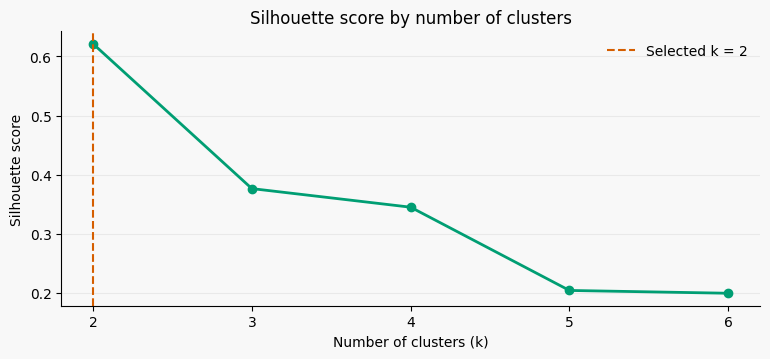

In [2]:
# Proviamo da 2 a 6 cluster e confrontiamo i silhouette score.
scores = {}

# Per ogni K addestriamo K-means e misuriamo la separazione dei gruppi.
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    pred = model.fit_predict(X)
    scores[k] = silhouette_score(X, pred)

# Scegliamo il K con il valore più alto tra quelli provati.
best_k = max(scores, key=scores.get)

# Addestriamo il modello definitivo sul profilo orario di ogni giorno.
km = KMeans(n_clusters=best_k, n_init=20, random_state=42)
labels = km.fit_predict(X)
print('Silhouette:', {k: round(v, 3) for k, v in scores.items()})
print('Chosen k:', best_k)
print('Cluster sizes:', pd.Series(labels).value_counts().sort_index().to_dict())

# Visualizziamo il confronto tra i valori di K.
fig, ax = plt.subplots(figsize=(7.8, 3.7))
ax.plot(list(scores), list(scores.values()), marker='o', color=CLUSTER_0, lw=2)
ax.axvline(best_k, color=ACCENT, ls='--', label=f'Selected k = {best_k}')
ax.set(title='Silhouette score by number of clusters',
       xlabel='Number of clusters (k)', ylabel='Silhouette score')
ax.set_xticks(list(scores)); ax.legend(frameon=False);ax.grid(axis='y', alpha=.2)
fig.tight_layout();fig.savefig(OUT/'RQ7A_k_selection.png',dpi=180,bbox_inches='tight');plt.show()

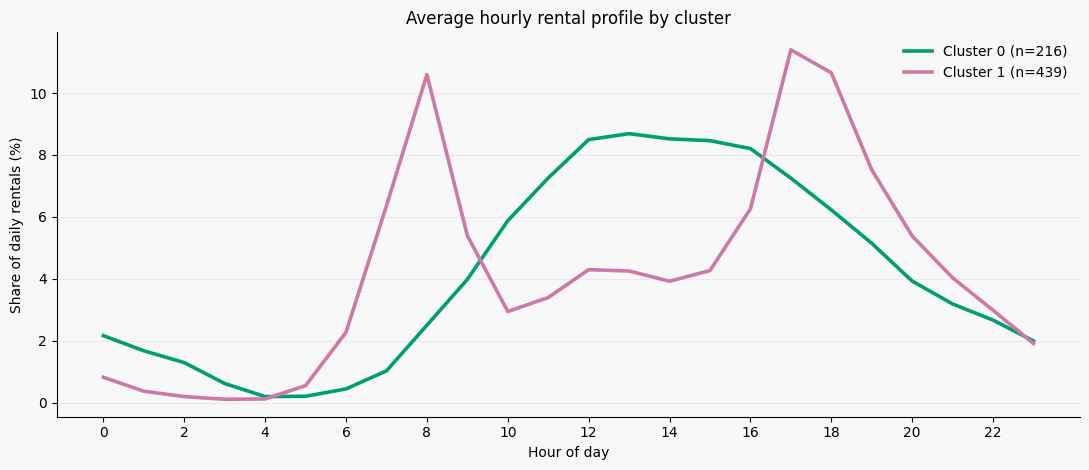

In [3]:
# Ricaviamo i profili orari medi dei gruppi e li convertiamo in percentuale.
centroids = pd.DataFrame(km.cluster_centers_, columns=range(24)) * 100
cluster_colors = CLUSTER_PALETTE

# Confrontiamo con due linee quando i diversi cluster usano le biciclette.
fig, ax = plt.subplots(figsize=(11,4.8))

# Mostriamo anche quanti giorni contiene ogni gruppo.
for i in centroids.index:
    ax.plot(centroids.columns,centroids.loc[i],label=f'Cluster {i} (n={(labels==i).sum()})',
            color=cluster_colors[i],lw=2.6)
ax.set(title='Average hourly rental profile by cluster',
       xlabel='Hour of day',ylabel='Share of daily rentals (%)')
ax.set_xticks(range(0,24,2));ax.grid(axis='y',alpha=.2)
ax.legend(frameon=False)

# Salviamo il grafico.
fig.tight_layout();fig.savefig(OUT/'RQ7B_cluster_profiles.png',dpi=200,bbox_inches='tight');plt.show()

PC1 explains 75.0% of variance, PC2 10.4%; total 85.4%


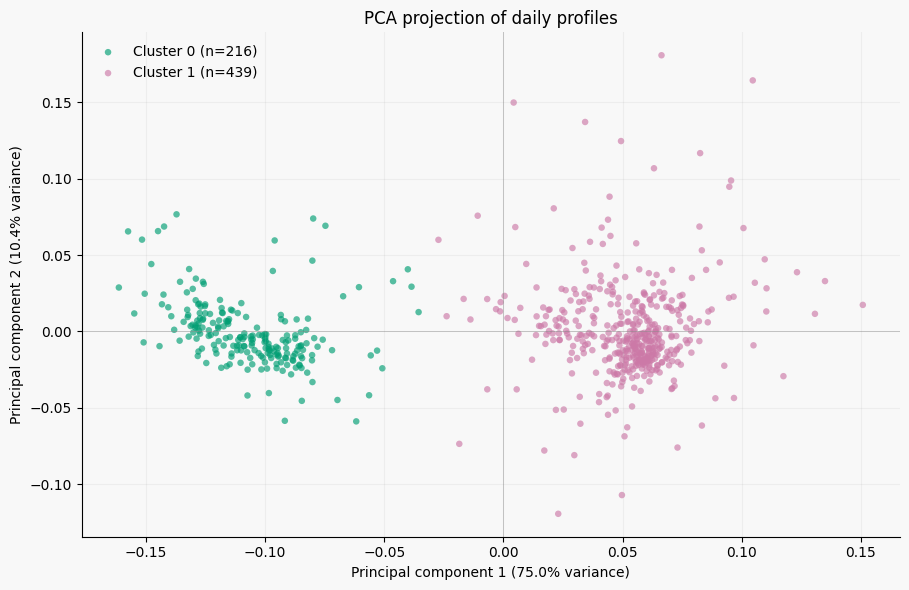

Five highest-absolute PC1 loadings (hour -> loading):
8     0.500
7     0.330
14   -0.295
13   -0.286
18    0.281
dtype: float64


In [4]:
# Usiamo PCA per proiettare 24 variabili in due dimensioni visualizzabili.
pca = PCA(n_components=2)

# Calcoliamo le coordinate e quanta variabilità manteniamo.
coordinates = pca.fit_transform(X)
explained = pca.explained_variance_ratio_ * 100
print(f'PC1 explains {explained[0]:.1f}% of variance, PC2 {explained[1]:.1f}%; total {explained.sum():.1f}%')

# Ogni punto è un giorno; il colore mostra il cluster assegnato prima da K-means.
fig,ax=plt.subplots(figsize=(9.2,6))

# Disegniamo separatamente i gruppi nella proiezione PCA.
for c in np.unique(labels):
    mask=labels==c
    ax.scatter(coordinates[mask,0],coordinates[mask,1],s=22,alpha=.65,
               label=f'Cluster {c} (n={mask.sum()})',color=cluster_colors[c],edgecolors='none')
ax.set(title='PCA projection of daily profiles',
       xlabel=f'Principal component 1 ({explained[0]:.1f}% variance)',
       ylabel=f'Principal component 2 ({explained[1]:.1f}% variance)')
ax.axhline(0,color='gray',lw=.7,alpha=.4);ax.axvline(0,color='gray',lw=.7,alpha=.4)
ax.grid(alpha=.15);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/'RQ7C_pca.png',dpi=200,bbox_inches='tight');plt.show()

# Controlliamo quali ore incidono maggiormente sulla prima componente.
loadings = pd.Series(pca.components_[0],index=range(24))
print('Five highest-absolute PC1 loadings (hour -> loading):')
print(loadings.reindex(loadings.abs().nlargest(5).index).round(3))

ARI with alternate initialization: 1.000
Bootstrap ARI: median 1.000, 10th–90th percentile [0.994, 1.000]


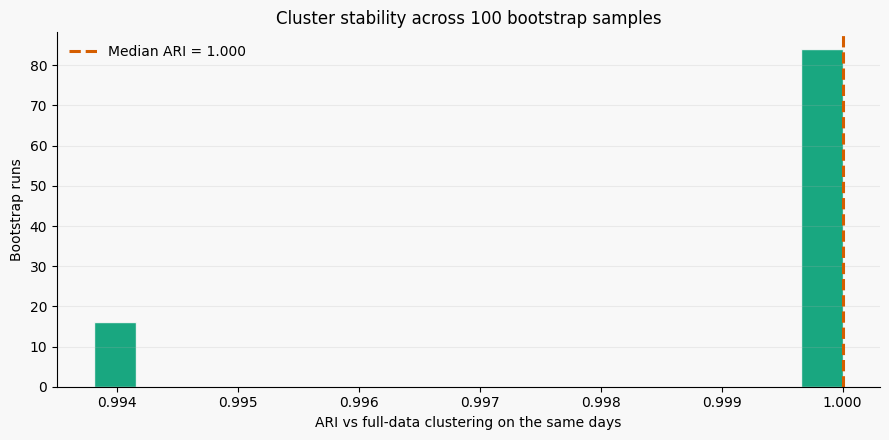

In [5]:
# Prepariamo il ricampionamento bootstrap con un seed riproducibile.
rng = np.random.default_rng(42)
X_arr = X.to_numpy()
bootstrap_ari = []

# Ripetiamo il controllo 100 volte per misurare la stabilità dei cluster.
N_BOOT = 100

# Riaddestriamo K-means su giornate estratte casualmente con reinserimento.
for run in range(N_BOOT):
    idx = rng.integers(0,len(X_arr),size=len(X_arr))
    new_km = KMeans(n_clusters=best_k,n_init=10,random_state=run)
    new_km.fit(X_arr[idx])
    predicted_all = new_km.predict(X_arr)  # same days as full-data reference
    bootstrap_ari.append(adjusted_rand_score(labels,predicted_all))

bootstrap_ari = np.array(bootstrap_ari)

# Verifichiamo anche se cambiare il seed modifica i cluster.
seed_model = KMeans(n_clusters=best_k,n_init=10,random_state=123).fit(X_arr)
seed_ari = adjusted_rand_score(labels,seed_model.predict(X_arr))
print(f'ARI with alternate initialization: {seed_ari:.3f}')
print(f'Bootstrap ARI: median {np.median(bootstrap_ari):.3f}, '
      f'10th–90th percentile [{np.percentile(bootstrap_ari,10):.3f}, '
      f'{np.percentile(bootstrap_ari,90):.3f}]')

# Mostriamo la distribuzione degli ARI: valori vicini a 1 indicano gruppi stabili.
fig,ax=plt.subplots(figsize=(9,4.5))
ax.hist(bootstrap_ari,bins=18,color=CLUSTER_0,edgecolor=BG,alpha=.9)
ax.axvline(np.median(bootstrap_ari),color=ACCENT,lw=2.2,ls='--',
           label=f'Median ARI = {np.median(bootstrap_ari):.3f}')
ax.set(title='Cluster stability across 100 bootstrap samples',
       xlabel='ARI vs full-data clustering on the same days',ylabel='Bootstrap runs')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'RQ7D_cluster_stability.png',dpi=200,bbox_inches='tight');plt.show()

CLUSTER EXPLANATION — information not used to fit K-means


,n_days,working_pct,avg_daily_rentals,median_daily_rentals,casual_share_pct,avg_temp_c,rainy_days_pct
cluster,,,,,,,
0,216,3.2,4507.7,4516.0,29.3,20.1,2.3
1,439,99.3,4927.9,4763.0,12.6,21.7,2.3


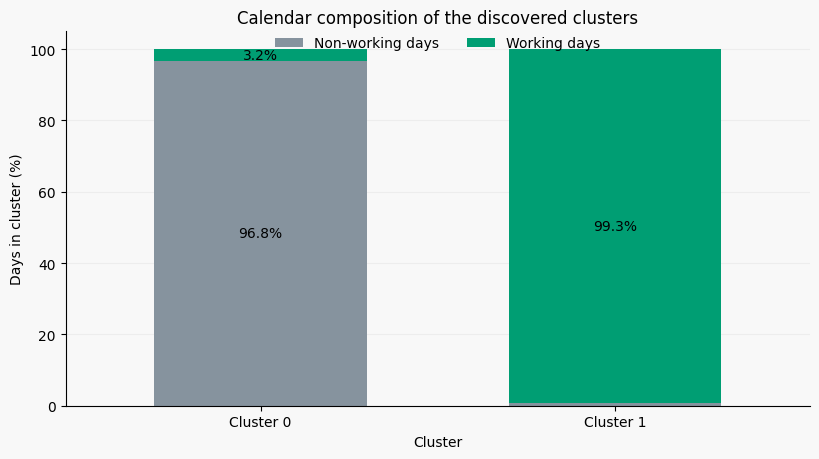

In [6]:
# Associamo i cluster ai giorni e alle informazioni esterne al modello.
results = pd.DataFrame({'cluster':labels},index=X.index)

# Allineiamo i dati giornalieri alle date effettivamente utilizzate.
meta = daily.reindex(results.index)
results['workingday'] = meta['workingday']
results['cnt'] = meta['cnt']

# Calcoliamo la percentuale di noleggi occasionali per ogni giorno.
results['casual_share_pct'] = meta['casual'] / meta['cnt'] * 100
results['temperature_c'] = meta['temp'] * 41
results['rainy_day'] = meta['weathersit'].ge(3).astype(int)
results['year'] = results.index.year

# Calcoliamo le percentuali di giorni lavorativi e non lavorativi nei cluster.
composition = (pd.crosstab(results['cluster'],results['workingday'],normalize='index')*100)
composition = composition.reindex(columns=[0,1],fill_value=0)
composition.columns=['Non-working days','Working days']

# Riassumiamo dimensione, domanda, temperatura e tipo di giornata per gruppo.
summary = results.groupby('cluster').agg(
    n_days=('cnt','size'),
    working_pct=('workingday',lambda v: 100*v.mean()),
    avg_daily_rentals=('cnt','mean'),
    median_daily_rentals=('cnt','median'),
    casual_share_pct=('casual_share_pct','mean'),
    avg_temp_c=('temperature_c','mean'),
    rainy_days_pct=('rainy_day',lambda v: 100*v.mean())
)
print('CLUSTER EXPLANATION — information not used to fit K-means')
display(summary.round(1))

# Mostriamo soltanto il calendario: la quota casual è approfondita nel grafico seguente.
fig, ax = plt.subplots(figsize=(8.3, 4.7))
composition[['Non-working days', 'Working days']].plot.bar(
    stacked=True, ax=ax, color=[NEUTRAL, CLUSTER_0], width=0.6
)
ax.set(title='Calendar composition of the discovered clusters',
       xlabel='Cluster', ylabel='Days in cluster (%)', ylim=(0, 105))
ax.set_xticklabels([f'Cluster {i}' for i in composition.index], rotation=0)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# Indichiamo soltanto le percentuali abbastanza grandi da essere leggibili.
for bars in ax.containers:
    labels_bars = [f'{bar.get_height():.1f}%' if bar.get_height() >= 2 else ''
                   for bar in bars]
    ax.bar_label(bars, labels=labels_bars, label_type='center', fontsize=10)
ax.grid(axis='y', alpha=0.15)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUT / 'RQ7E_posthoc_explanation.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
# Importiamo i test necessari per spiegare statisticamente i cluster.
from scipy.stats import kruskal, chi2_contingency, fisher_exact, false_discovery_control

# Prepariamo le variabili esterne: calendario, meteo e composizione degli utenti.
meta_test = results.copy()
meta_test['humidity_pct'] = meta['hum'] * 100
meta_test['season_name'] = pd.Categorical(
    results.index.month.map({
        12:'Winter', 1:'Winter', 2:'Winter',
        3:'Spring', 4:'Spring', 5:'Spring',
        6:'Summer', 7:'Summer', 8:'Summer',
        9:'Autumn', 10:'Autumn', 11:'Autumn'
    }), categories=['Winter','Spring','Summer','Autumn'], ordered=True
)

# Recuperiamo i nomi numerici dei gruppi, che sono arbitrari.
cluster_ids = sorted(meta_test['cluster'].unique())
n_clusters = len(cluster_ids)

# Scegliamo le variabili numeriche da confrontare tra cluster.
numeric_vars = {
    'casual_share_pct': 'Casual share (%)',
    'cnt': 'Daily rentals',
    'temperature_c': 'Temperature (°C)',
    'humidity_pct': 'Humidity (%)',
}

# Scegliamo le variabili categoriali da confrontare.
categorical_vars = {
    'workingday': 'Working day',
    'season_name': 'Meteorological season',
    'rainy_day': 'Rain / snow (daily)',
    'year': 'Calendar year',
}

rows = []

# Per le variabili numeriche applichiamo Kruskal–Wallis e calcoliamo ε².
for col, label in numeric_vars.items():
    groups = [meta_test.loc[meta_test['cluster'] == cid, col].dropna().to_numpy()
              for cid in cluster_ids]
    H, p = kruskal(*groups)
    n = sum(len(v) for v in groups)
    epsilon2 = max(0.0, (H - n_clusters + 1) / (n - n_clusters))
    record = {'feature':label, 'variable':col, 'kind':'numeric',
              'test':'Kruskal–Wallis', 'statistic':H, 'effect':epsilon2,
              'effect_name':'ε²', 'p_value':p}
    for cid, group in zip(cluster_ids, groups):
        record[f'cluster_{cid}_median'] = float(np.median(group))
        record[f'cluster_{cid}_n'] = len(group)
    rows.append(record)

# Per le categorie usiamo chi-quadrato o Fisher e calcoliamo Cramér V.
for col, label in categorical_vars.items():
    tab = pd.crosstab(meta_test['cluster'], meta_test[col])
    if min(tab.shape) < 2:
        continue
    chi2, p_chi, _, expected = chi2_contingency(tab, correction=False)
    n = tab.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape)-1)))
    if tab.shape == (2,2) and (expected < 5).any():
        _, p = fisher_exact(tab.to_numpy())
        test_name = 'Fisher exact'
    else:
        p = p_chi
        test_name = 'Chi-square'
    rows.append({'feature':label, 'variable':col, 'kind':'categorical',
                 'test':test_name, 'statistic':chi2, 'effect':v,
                 'effect_name':"Cramér's V", 'p_value':p})

# Raccogliamo risultati, p-value e dimensioni dell’effetto in una tabella.
posthoc = pd.DataFrame(rows)

# Correggiamo i p-value con Benjamini–Hochberg perché facciamo più test.
posthoc['q_BH'] = false_discovery_control(posthoc['p_value'].to_numpy(), method='bh')
posthoc['FDR_5pct'] = posthoc['q_BH'] < 0.05
posthoc = posthoc.sort_values(['kind','effect'], ascending=[True,False]).reset_index(drop=True)

# Stampiamo test, significatività e mediane per ogni cluster.
print('EXTERNAL CLUSTER ASSOCIATIONS (FDR corrected; higher effect = stronger association)')
display(posthoc[['feature','kind','test','effect_name','effect','p_value','q_BH','FDR_5pct']]
        .style.format({'effect':'{:.3f}', 'p_value':'{:.2e}', 'q_BH':'{:.2e}'}))

print('NUMERIC MEDIANS PER CLUSTER')
medians = meta_test.groupby('cluster')[list(numeric_vars)].median().rename(columns=numeric_vars)
display(medians.round(2))

# Esportiamo le tabelle per poterle utilizzare nella presentazione.
posthoc.to_csv(OUT/'RQ7H_posthoc_statistics.csv', index=False)
medians.to_csv(OUT/'RQ7I_cluster_numeric_medians.csv')

print('CLUSTER SIZES:', meta_test['cluster'].value_counts().sort_index().to_dict())

EXTERNAL CLUSTER ASSOCIATIONS (FDR corrected; higher effect = stronger association)


,feature,kind,test,effect_name,effect,p_value,q_BH,FDR_5pct
0,Working day,categorical,Chi-square,Cramér's V,0.965,8.94e-135,7.15e-134,True
1,Meteorological season,categorical,Chi-square,Cramér's V,0.089,1.58e-01,2.53e-01,False
2,Calendar year,categorical,Chi-square,Cramér's V,0.009,8.13e-01,9.29e-01,False
3,Rain / snow (daily),categorical,Fisher exact,Cramér's V,0.001,1.00e+00,1.00e+00,False
4,Casual share (%),numeric,Kruskal–Wallis,ε²,0.425,1.79e-62,7.15e-62,True
5,Temperature (°C),numeric,Kruskal–Wallis,ε²,0.009,7.90e-03,1.86e-02,True
6,Daily rentals,numeric,Kruskal–Wallis,ε²,0.009,9.31e-03,1.86e-02,True
7,Humidity (%),numeric,Kruskal–Wallis,ε²,0.000,6.43e-01,8.57e-01,False


NUMERIC MEDIANS PER CLUSTER


,Casual share (%),Daily rentals,Temperature (°C),Humidity (%)
cluster,,,,
0,32.11,4516.0,19.48,62.25
1,13.46,4763.0,22.35,63.29


CLUSTER SIZES: {0: 216, 1: 439}


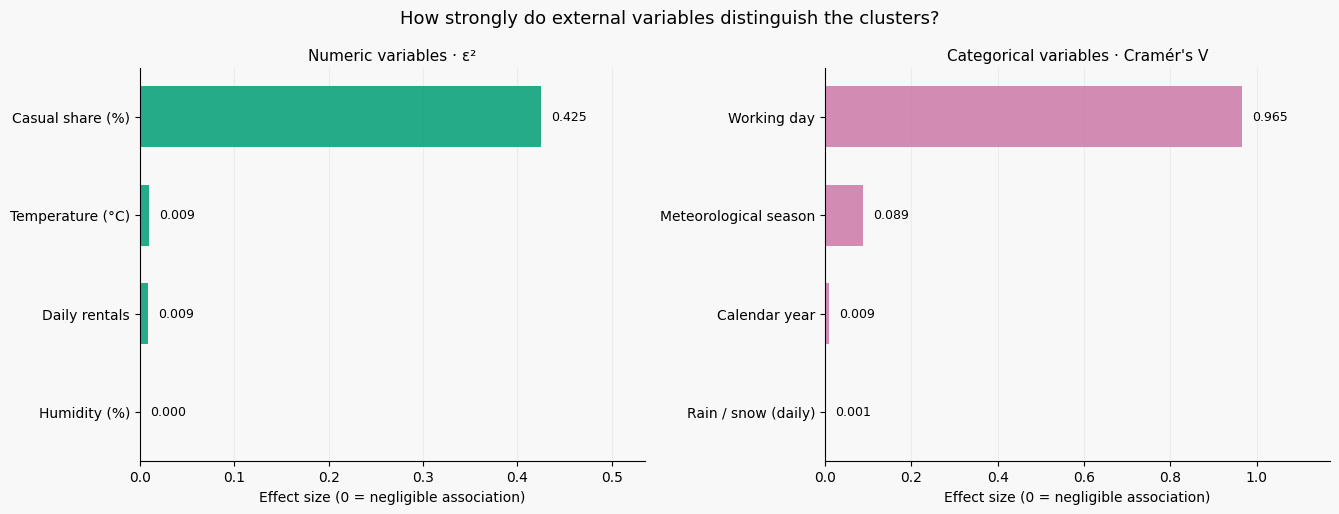

In [8]:
# Disegniamo due grafici distinti: ε² e Cramér V hanno interpretazioni diverse.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Ordiniamo le variabili per dimensione dell’effetto.
for ax, kind, title, clr in zip(
    axes,
    ['numeric','categorical'],
    ['Numeric variables · ε²',
     "Categorical variables · Cramér's V"],
    [CLUSTER_0,CLUSTER_1]
):
    selected = posthoc[posthoc['kind'] == kind].sort_values('effect')
    names = selected['feature'].tolist()
    vals = selected['effect'].to_numpy()
    ax.barh(names, vals, color=clr, alpha=.85, height=.62)
    ax.set_xlim(0, max(.12, float(vals.max())*1.26) if kind == 'numeric' else 1.17)
    ax.set_xlabel('Effect size (0 = negligible association)')
    ax.set_title(title, fontsize=11)
    ax.grid(axis='x', alpha=.16)
    ax.set_axisbelow(True)
    # Le significatività restano nelle tabelle: sul grafico bastano le dimensioni dell'effetto.
    for i, effect in enumerate(vals):
        ax.text(effect + ax.get_xlim()[1]*0.02, i, f'{effect:.3f}',
                va='center', fontsize=9)

# Aggiungiamo una nota sui test e salviamo la figura.
fig.suptitle('How strongly do external variables distinguish the clusters?', fontsize=13)
fig.tight_layout()
fig.savefig(OUT/'RQ7F_external_effect_sizes.png', dpi=200, bbox_inches='tight')
plt.show()

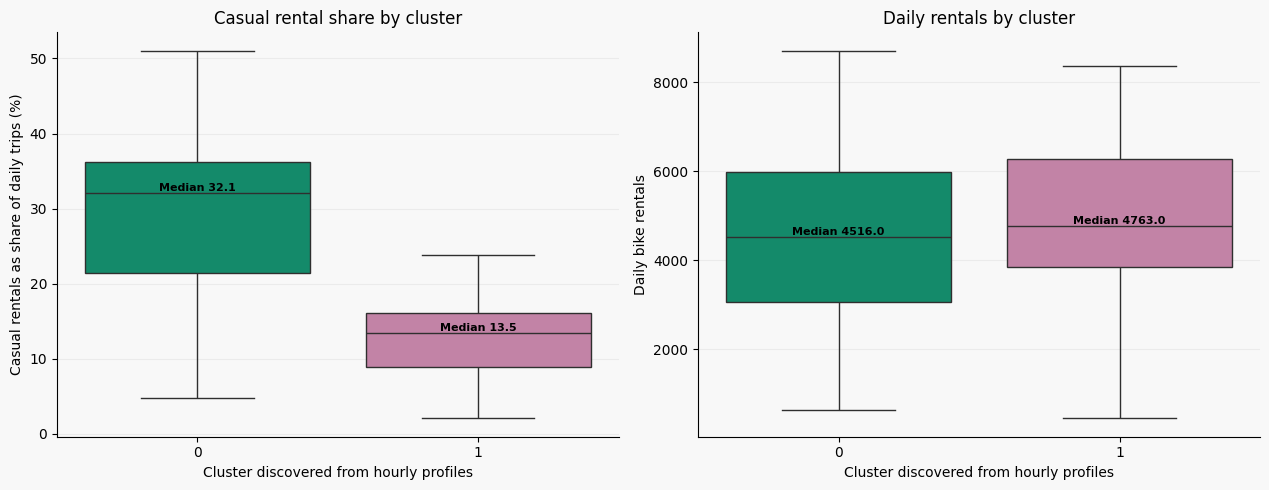

PERCENTAGE OF WORKING / NON-WORKING DAYS WITHIN EACH CLUSTER


workingday,Non-working (%),Working (%)
cluster,,
0,96.8,3.2
1,0.7,99.3


In [9]:
# Usiamo due box plot per visualizzare le differenze tra i gruppi.
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5))

# Confrontiamo quota occasionali e noleggi totali, non usati per creare i cluster.
plot_vars = [('casual_share_pct','Casual rentals as share of daily trips (%)',
              'Casual rental share by cluster'),
             ('cnt','Daily bike rentals',
              'Daily rentals by cluster')]

# Mostriamo distribuzioni e mediane, senza disegnare tutti gli outlier.
for ax, (col, ylab, title) in zip(axes, plot_vars):
    sns.boxplot(data=meta_test, x='cluster', y=col, order=cluster_ids,
                hue='cluster', palette={i:cluster_colors[i] for i in cluster_ids},
                legend=False, showfliers=False, ax=ax)
    ax.set(xlabel='Cluster discovered from hourly profiles', ylabel=ylab, title=title)
    ax.grid(axis='y', alpha=.18)
    ax.set_axisbelow(True)
    for i, cid in enumerate(cluster_ids):
        v = meta_test.loc[meta_test.cluster == cid, col]
        ax.text(i, v.median(), f'Median {v.median():.1f}', ha='center',va='bottom',
                fontsize=8, fontweight='bold')
fig.tight_layout()
fig.savefig(OUT/'RQ7G_cluster_external_profiles.png', dpi=200, bbox_inches='tight')
plt.show()

# Stampiamo infine le percentuali di giorni lavorativi e non lavorativi.
print('PERCENTAGE OF WORKING / NON-WORKING DAYS WITHIN EACH CLUSTER')
display((pd.crosstab(meta_test.cluster, meta_test.workingday,
                    normalize='index')*100).rename(columns={0:'Non-working (%)',1:'Working (%)'}).round(1))